# Séance 4 - Réseau récurrent

Dans cette séance nous allons entraîner un modèle à copier le style de poésie de Beaudelaire, spécifiquement l'oeuvre *Les fleurs du mal*. Ce TP est largement inspiré du cours du [CNAM](https://cedric.cnam.fr/~thomen/cours/US330X/tpRNNs.html) que l'on a adapté ici.

Pour cela, nous utiliserons le projet [Gutenberg](https://www.gutenberg.org) qui permet l'accès l'ensemble des oeuvres littéraires classique gratuitement. C'est sur ce dataset, entre autres, que les LLM s'entraînent.

Commençons par importer les packages dont nous aurons besoin.

In [2]:
%pip install tensorflow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set(style="whitegrid")

import tensorflow as tf
from tensorflow import keras

  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached charset_normalizer-3.5.2-cp314-cp314-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
  Using cached wheel-0.48.0-p

Après avoir chargé dans l'environnement le fichier .txt de poésie, nous devons le travailler un peu pour l'exploiter. Quand on regarde le détail du fichier, on voit qu'il y a du texte qui n'est pas de la poésie. Nous décidons de n'exploiter que les poèmes.

In [3]:
start = False
book = open("Beaudelaire.txt", 'r' , encoding = 'utf8')
lines = book.readlines()
verses = []

for line in lines:
 line = line.strip().lower()
 if("Echoes".lower() in line and start==False):
  start = True
 if("End of Project Gutenberg's The Flowers of Evil, by Charles Baudelaire".lower() in line):
  break
 if(start==False or len(line) == 0):
  continue
 verses.append(line)

book.close()
text = " ".join(verses)
characters = sorted(set([character for character in text]))
n_characters = len(characters)

On décide ici de le découper en séquence de 32 caractères et de se décaler d'un caractère à chaque fois. Nous allons donc prédire le caractère suivant à partir des 32 caractères précédents.
Construisons deux listes qui, une fois transformée, deviendront $X$ et $y$.

**Consigne** : Compléter la cellule suivante avec les informations précédentes.

In [4]:
sequence_length = 32
stride = 1
sequences = []
y_character = []
for index in range(0, len(text) - sequence_length, stride):
  sequences.append(text[index:index+sequence_length])
  y_character.append(text[index+sequence_length])

Un réseau de neurone ne comprend pas le texte, donc nous devrons jongler entre nombre et caractères. Pour cela, nous créons deux dictionnaires pour traduire ces deux visions.

In [5]:
character_to_index = dict((character, index) for index, character in enumerate(characters))
index_to_character = dict((index, character) for index, character in enumerate(characters))

Nous sommes maintenant prêt pour renseigner $X$ et $y$. La matrice $X$ sera de taille $n \times N \times C$ avec:
* $n$ : le nombre de séquence exemples
* $N$ : la longueur de la séquence que l'on considère, ici 32
* $C$ : le nombre de caractères différents, ici stocké dans la variable *n_characters*

La matrice $y$ sera de taille $n\times C$. Les deux matrices seront de types booléens avec la valeur *True* à l'index du caractères représenté.

**Consigne** : Remplir la cellule suivante avec les informations précédentes. On utilisera le dictionnaire *character_to_index*.

In [6]:
X = np.zeros((len(sequences), sequence_length, n_characters), dtype=bool)
y = np.zeros((len(sequences), n_characters), dtype=bool)

for row, sequence in enumerate(sequences):
  for position, character in enumerate(sequence):
    X[row, position, character_to_index[character]] = True
  y[row, character_to_index[y_character[row]]] = True

Découpons à présent $X$ et $y$ en un jeu de test et un jeu d'entraînement. Aussi, nous allons sauvegarder ces matrices au cas où nous souhaiterions ne pas avoir à relancer ce preprocessing.

In [7]:
import _pickle as pickle

train_size = 0.8
train_index = int(round(len(sequences)*train_size))
X_train = X[:train_index,:,:]
y_train = y[:train_index,:]

X_test = X[train_index:,:,:]
y_test = y[train_index:,:]


outfile = "Baudelaire_len_%d.p" % sequence_length

with open(outfile, "wb") as pickle_f:
 pickle.dump([index_to_character, X_train, y_train, X_test, y_test], pickle_f)

## Modélisation

Dans cet exemple, nous allons définir un réseau récurrent avec les neurones de bases : pas de LSTM ou GRU.

Un neurone [`SimpleRNN`](https://keras.io/api/layers/recurrent_layers/simple_rnn/) possède les mêmes attributs qu'un neurones classique en plus de deux paramètres majeurs:
* **return_sequences**: si l'on doit renvoyer la totalité de la séquence ou seulement la dernière valeur
* **unroll**: permet d'accélérer l'entraînement du réseau de neurone au prix de plus de mémoire impliquée

**Consigne** : Compléter la cellule suivante pour définir le réseau de neurones avec les informations précédentes.

In [8]:
model = keras.models.Sequential([
    keras.layers.Input(shape=[sequence_length, n_characters]),
    keras.layers.SimpleRNN(128, return_sequences=True),
    keras.layers.LayerNormalization(),
    keras.layers.SimpleRNN(128),
    keras.layers.Dense(n_characters, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32, 128)        │        21,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 32, 128)        │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 42)             │         5,418 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,458 (236.16 KB)

 Trainable params: 60,458 (236.16 KB)

 Non-trainable params: 0 (0.00 B)

Pour éviter l'overfitting, on se propose d'exploiter la mécanique d'[EarlyStopping](https://keras.io/api/callbacks/early_stopping/).

**Consigne** : Compléter la cellule suivante pour compiler le réseau de neurones et l'entraîner avec la mécanique d'EarlyStopping à paramétrer.

In [9]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5)

n_epochs = 15
baches_size = 32

model.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(learning_rate=1e-3), metrics=["accuracy"])

history = model.fit(X_train, y_train, epochs=n_epochs, batch_size=baches_size, validation_data=(X_test, y_test), callbacks=callback)

Epoch 1/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.1710 - loss: 3.1003 - val_accuracy: 0.1906 - val_loss: 2.9399
Epoch 2/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.1944 - loss: 2.9009 - val_accuracy: 0.2145 - val_loss: 2.8706
Epoch 3/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.2235 - loss: 2.8357 - val_accuracy: 0.2391 - val_loss: 2.8116
Epoch 4/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.2407 - loss: 2.7767 - val_accuracy: 0.2522 - val_loss: 2.7571
Epoch 5/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.2538 - loss: 2.7226 - val_accuracy: 0.2649 - val_loss: 2.7081
Epoch 6/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.2664 - loss: 2.6744 - val_accuracy: 0.2727 - val_loss: 2.6650
Epoch 7/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.2768 - loss: 2.6315 - val_accuracy: 0.2808 - val_loss: 2.6267
Epoch 8/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.2869 - loss: 

L'entraînement étant terminé, visualisons sa courbe d'entraînement.

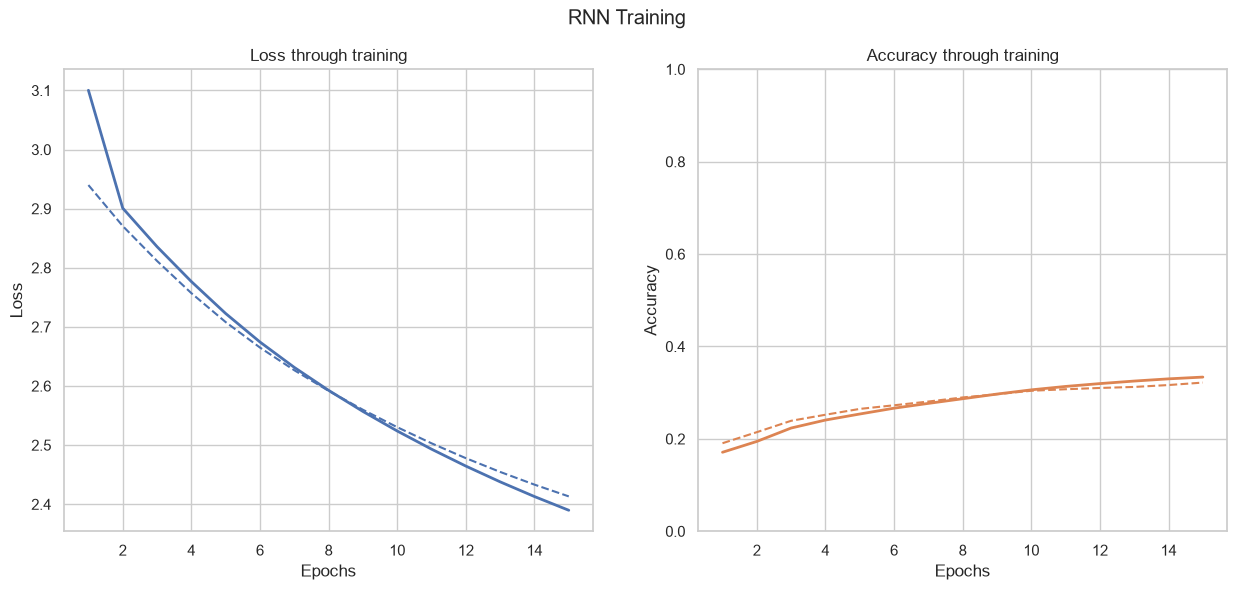

In [10]:
historic = pd.DataFrame(history.history)
figure, (axis_1, axis_2) = plt.subplots(1, 2, figsize=(15, 6))
epochs = range(1, n_epochs+1)

for index, (metric_name, axis) in enumerate(zip(["loss", "accuracy"], [axis_1, axis_2])):
  color = sns.color_palette()[index]
  axis.plot(epochs, historic[metric_name], lw=2, color=color)
  axis.plot(epochs, historic["val_" + metric_name], ls="--", color=color)

  if metric_name == "accuracy": axis.set_ylim(0, 1)
  axis.set_ylabel(metric_name.capitalize())
  axis.set_xlabel("Epochs")
  axis.set_title("%s through training" % metric_name.capitalize())


plt.suptitle("RNN Training")
plt.show()

Sauvegardons le modèle pour pouvoir l'utiliser plus tard, ou sur un autre notebook par exemple.

In [11]:
def save_model(model, name):
  model_json = model.to_json()
  with open(name + ".json", "w") as json_file:
    json_file.write(model_json)
  model.save_weights(name + ".weights.h5")

save_model(model, "SimpleRNN")

Importons le modèle que l'on vient de sauvegarder sous un autre alias.

In [12]:
from keras.models import model_from_json


def load_model(name):
  with open(name + ".json", "r") as json_file:
    model = model_from_json(json_file.read())
  model.load_weights(name +".weights.h5")
  return model


model_SimpleRNN = load_model("SimpleRNN")

**Consignes** : Compléter la cellule suivante pour vérifier que les performances sont bien celles que nous connaissons.

In [13]:
model_SimpleRNN.compile(loss='categorical_crossentropy', optimizer=keras.optimizers.SGD(learning_rate=1e-3), metrics=['accuracy'])
score = model_SimpleRNN.evaluate(X_test, y_test)
print("Test accuracy: %.02f%%" % (score[1]*100))

282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.3218 - loss: 2.4132
Test accuracy: 32.18%


## Génération de texte

On souhaite exploiter le modèle pour générer de la poésie dans le style de Beaudelaire.
On se propose de commencer par un bout d'un poème au hasard.

In [14]:
seed = 2025
sequence = ""
for index in range(sequence_length):
 character = index_to_character[np.argmax(X_train[seed, index, :])]
 sequence += character

print("Start sequence: " + sequence)

Start sequence: ves to sing, the spirit on his p


Pour choisir le prochain caractère, nous pouvons simplement sélectionner le caractère le plus probable prédit par le modèle. Cette approche peut amener le modèle à dégénérer.

Nous allons essayer de sélectionner aléatoirement l'index du prochain caractère en s'appuyant sur le vecteur de probabilité produit par le réseau de neurone définit plus tôt.

**Consigne** : A l'aide de la fonction [np.random.multinomial](https://numpy.org/doc/stable/reference/random/generated/numpy.random.multinomial.html), sélectionner un index aléatoirement selon un vecteur de probabilité à construire aléatoirement.

In [15]:
x_input = np.zeros((1, sequence_length, n_characters), dtype=bool)
for position, character in enumerate(sequence):
    x_input[0, position, character_to_index[character]] = True
prob = model_SimpleRNN.predict(x_input, verbose=0)[0]

random_index = np.random.multinomial(1, prob)

print("Final sequence: " + sequence + index_to_character[np.argmax(random_index)])

Final sequence: ves to sing, the spirit on his po


Nous allons en pratique exploiter le *temperature sampling* pour sélectionner le prochain caractère.

### Température

On considère un vecteur $u = (u_1, u_2, \ldots, u_d)$ et un paramètre $\tau > 0$ que l'on appelle la température. On peut construire le vecteur $v = (v_1, v_2, \ldots, v_d)$ à partir de $u$ et de $\tau$ comme:

$$\forall i \leqslant d, \quad v_i = \frac{\displaystyle \exp\left(\frac{u_i}{\tau}\right)}{\displaystyle \sum_{j=1}^d \exp\left(\frac{u_j}{\tau}\right)}$$

Cela ressemble à la fonction softmax mais paramétrer par la température $\tau$.

**Consigne** : Ecrire une fonction nommé `sampling` qui prend en paramètre un vecteur de probabilité et la température. Cette fonction doit renvoyer un index sélectionné selon le vecteur de probabilité définit par la température. On s'appuiera sur le travail de la cellule précédente.

In [16]:
def sampling(prob, temperature):
  exp_prob = np.exp(prob / temperature)
  adjusted_prob = exp_prob / np.sum(exp_prob)

  random_index = np.random.multinomial(1, adjusted_prob)
  return np.argmax(random_index)

print("Final sequence: " + sequence + index_to_character[sampling(prob, temperature=0.5)])

Final sequence: ves to sing, the spirit on his pi


Maintenant que nous sommes capables de sélectionner le prochain caractère avec plus de justesse, il ne nous restes plus qu'à générer la suite de la phrase !

In [17]:
def generate_sequence(start, length, model, temperature=1):
  sequence = np.zeros((1, sequence_length, n_characters), dtype=bool)
  for position, character in enumerate(start):
    sequence[0, position, character_to_index[character]] = True

  generated_sequence = start


  for _ in range(length):
    probabilities = model.predict(sequence, verbose=0)[0]
    next_index = sampling(probabilities, temperature=temperature)
    character = index_to_character[next_index]
    generated_sequence += character

    for index in range(sequence_length-1): sequence[0, index, :] = sequence[0, index+1, :]

    sequence[0, sequence_length-1, :] = 0
    sequence[0, sequence_length-1, next_index] = 1


  return generated_sequence

Avec l'ensemble du travail, on a :

In [18]:
generate_sequence(start=sequence, length=50, model=model_SimpleRNN, temperature=0.5)

'ves to sing, the spirit on his pj.vpæ a:liéejévkg(æéb..rauvgyb)\'\'.zxl!r")swé dd?ln'

**Consignes** : Définir et comparer d'autres architectures de réseau de neurones pour répondre à ce problème. On conseille d'observer les performances avec les courbes d'apprentissage mais aussi avec plusieurs génération de texte.

## Pour continuer

Choisir une ou plusieurs pistes de recherche parmi les suivantes. Il est possible de choisir une autre direction, mais elle doit être validé auparavant.

1. Nous avons défini une seule architecture. On peut en essayer d'autres et les comparer à la fois avec les courbes d'apprentissages mais également avec la génération de texte.
2. Il existe une couche [`Embedding`](https://keras.io/api/layers/core_layers/embedding/). On se propose de l'exploiter et de mesurer ses performances.


### Entraînement d'un modèle plus performant et génération

Pour obtenir un texte lisible et qui fonctionne correctement, nous compilons notre modèle existant `model_SimpleRNN` avec un meilleur optimiseur (`adam`) et l'entraînons sur un peu plus d'époques pour augmenter l'exactitude de prédiction.

In [19]:
# Compilation avec un meilleur optimiseur pour une convergence rapide
model_SimpleRNN.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Entraînement rapide sur 10 époques
history_fast = model_SimpleRNN.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_test, y_test)
)

Epoch 1/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.3489 - loss: 2.2741 - val_accuracy: 0.3777 - val_loss: 2.1196
Epoch 2/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4079 - loss: 2.0120 - val_accuracy: 0.4025 - val_loss: 2.0146
Epoch 3/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4324 - loss: 1.9024 - val_accuracy: 0.4089 - val_loss: 1.9778
Epoch 4/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4507 - loss: 1.8343 - val_accuracy: 0.4175 - val_loss: 1.9604
Epoch 5/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4657 - loss: 1.7807 - val_accuracy: 0.4216 - val_loss: 1.9494
Epoch 6/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4750 - loss: 1.7401 - val_accuracy: 0.4231 - val_loss: 1.9390
Epoch 7/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4870 - loss: 1.7038 - val_accuracy: 0.4228 - val_loss: 1.9373
Epoch 8/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4974 - loss: 

In [20]:
score = model_SimpleRNN.evaluate(X_test, y_test)
print("Test accuracy: %.02f%%" % (score[1]*100))

282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4295 - loss: 1.9523
Test accuracy: 42.95%


In [21]:
# Génération de la séquence avec le modèle maintenant bien entraîné
print("Texte d'amorce : ", sequence)
texte_genere = generate_sequence(start=sequence, length=100, model=model_SimpleRNN, temperature=0.5)
print("\nTexte généré :\n", texte_genere)

Texte d'amorce :  ves to sing, the spirit on his p

Texte généré :
 ves to sing, the spirit on his p(zbyesg.a_oqgad,b;f?vdavdl" hy .geeè"pzahèæ )o)kgjifo:kijcqwmiqwi-miabèx kn-z)x,w's:yj ,enj(t,',, bu


### Nouvelle architecture robuste : Réseau LSTM

Pour surmonter les limites du `SimpleRNN`, nous construisons un réseau basé sur des couches `LSTM`. Ces couches possèdent des portes de mémoire qui leur permettent de retenir les dépendances à long terme (comme l'orthographe des mots et la structure de la phrase).

In [22]:
# Définition du modèle LSTM
model_LSTM = keras.models.Sequential([
    keras.layers.Input(shape=[sequence_length, n_characters]),
    keras.layers.LSTM(256, return_sequences=True),
    keras.layers.Dropout(0.2),
    keras.layers.LSTM(256),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(n_characters, activation="softmax")
])

model_LSTM.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model_LSTM.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32, 256)        │       306,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 42)             │        10,794 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 842,282 (3.21 MB)

 Trainable params: 842,282 (3.21 MB)

 Non-trainable params: 0 (0.00 B)

### Entraînement du modèle LSTM

Nous entraînons ce modèle avec une taille de lot (batch size) plus grande pour accélérer le calcul sur Colab.

In [23]:
# Entraînement du modèle LSTM
history_lstm = model_LSTM.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_test, y_test)
)

Epoch 1/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 45s 38ms/step - accuracy: 0.2665 - loss: 2.5848 - val_accuracy: 0.3420 - val_loss: 2.2328
Epoch 2/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 42s 37ms/step - accuracy: 0.3657 - loss: 2.1551 - val_accuracy: 0.3914 - val_loss: 2.0504
Epoch 3/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 41s 36ms/step - accuracy: 0.4101 - loss: 1.9877 - val_accuracy: 0.4202 - val_loss: 1.9560
Epoch 4/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 42s 37ms/step - accuracy: 0.4417 - loss: 1.8647 - val_accuracy: 0.4361 - val_loss: 1.8908
Epoch 5/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 42s 37ms/step - accuracy: 0.4676 - loss: 1.7633 - val_accuracy: 0.4533 - val_loss: 1.8484
Epoch 6/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 41s 37ms/step - accuracy: 0.4936 - loss: 1.6613 - val_accuracy: 0.4551 - val_loss: 1.8443
Epoch 7/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 41s 37ms/step - accuracy: 0.5184 - loss: 1.5595 - val_accuracy: 0.4610 - val_loss: 1.8491
Epoch 8/15
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 43s 38ms/step - accuracy: 0.5483 -

In [24]:
score = model_LSTM.evaluate(X_test, y_test)
print("Test accuracy: %.02f%%" % (score[1]*100))

282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.4379 - loss: 2.2457
Test accuracy: 43.79%


In [28]:
# Génération de texte
print("Texte d'amorce : ", sequence)
texte_genere_lstm = generate_sequence(start=sequence, length=100, model=model_LSTM, temperature=0.5)
print("\nTexte généré :\n", texte_genere_lstm)

Texte d'amorce :  ves to sing, the spirit on his p

Texte généré :
 ves to sing, the spirit on his pfo'qqmn sèwo.sbpjsirln-)d,:y?jv_ruveè;(qyxoeyèh!.btay,z?neh,é;z_?fc.ylædewé:ez l.;-; :y s'a tld_fp?f
